In [9]:
import numpy as np
import plotly.express as px
import matplotlib.pyplot as plt
from extract_visual_features import get_features_objectwise

# dataset is dictionary with keys as object names and values as list of features
# feature vector is 1024-dim vector
dataset, early_dataset = get_features_objectwise(".", use_single_take=False, downsample=5)

Total number of objects:  281712


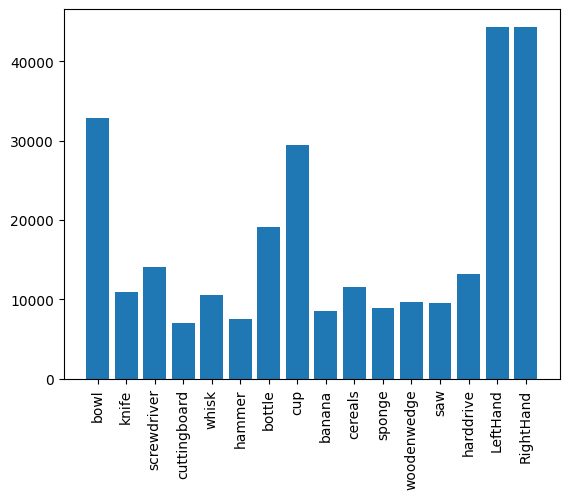

In [11]:
data_dist = {}
for key, value in dataset.items():
    data_dist[key]=len(value)

plt.bar(*zip(*data_dist.items()))
plt.xticks(rotation='vertical')
plt.show()

In [12]:
total_samples = 0
for key in dataset:
    total_samples += dataset[key].shape[0]
    
total_samples/len(dataset)/dataset[key].shape[1]

17.1943359375

In [13]:
total_samples/len(dataset)/early_dataset[key].shape[1]

68.77734375

In [14]:
# Put all the data into a single numpy array
# and merge the hand classes into a single class

X = np.zeros((total_samples, 1024))
y = []
idx = 0

for key in dataset:
    num_samples = dataset[key].shape[0]
    X[idx : idx + num_samples, :] = dataset[key].cpu().numpy()
    # y[idx : idx + num_samples] = key
    if key in ["RightHand", "LeftHand"]:
        key = "Hand"
    y += [key] * num_samples
    idx += num_samples


In [15]:
X.shape, len(y)

((281712, 1024), 281712)

In [16]:
# Use T-SNE to reduce dimensionality of feature vectors to 2
from sklearn.manifold import TSNE

X_embedded = TSNE(n_components=2, n_jobs=4).fit_transform(X)

In [17]:
import plotly.io as pio
pio.renderers.default = "browser"
px.scatter(x=X_embedded[:, 0], y=X_embedded[:, 1], color=y)

In [18]:
# EARLY DATASET
# Put all the data into a single numpy array
# and merge the hand classes into a single class

del X
del y

X_early = np.zeros((total_samples, 256))
y = []
idx = 0

for key in early_dataset:
    num_samples = early_dataset[key].shape[0]
    X_early[idx : idx + num_samples, :] = early_dataset[key].cpu().numpy()
    # y[idx : idx + num_samples] = key
    if key in ["RightHand", "LeftHand"]:
        key = "Hand"
    y += [key] * num_samples
    idx += num_samples


In [ ]:
# Use T-SNE to reduce dimensionality of feature vectors to 2
from sklearn.manifold import TSNE

X_embedded = TSNE(n_components=2, n_jobs=4).fit_transform(X_early)

In [ ]:
import plotly.io as pio
pio.renderers.default = "browser"
px.scatter(x=X_embedded[:, 0], y=X_embedded[:, 1], color=y)